In [56]:
import pandas as pd
import matplotlib.pyplot as plt

# Carrega o corpus consolidado
df = pd.read_csv("/home/mariana/Projetinhos pessoais/projeto-extra-favelas/data/corpus_favela_extra.csv")

# Exibe as 5 primeiras linhas para conferir se a tabela subiu certinha
display(df.head())
print(f"Dimensões da tabela: {df.shape[0]} linhas e {df.shape[1]} colunas.")

,arquivo,titulo,subtitulo,url,ano_mes,texto
0,materia_013.txt,Terceira edição do Fórum EXTRA Favelas debate ...,Evento será transmitido ao vivo pelo YouTube e...,https://extra.globo.com/extra-favelas/noticia/...,2026-11,"O jornal EXTRA sediou, nesta terça-feira (3), ..."
1,materia_117.txt,De 'proibidão' a Gangnam Style: no dia do K-Po...,"Nos bastidores, cantora brincou que tem esquec...",https://extra.globo.com/entretenimento/rock-in...,2026-09,"“Quem não dançar é sete anos sem fu…”, avisou ..."
2,materia_103.txt,"Ex-'nerd gordinho', cantor que virou sensação ...",Puterrier lotou o Espaço Favela e chamou atenç...,https://extra.globo.com/famosos/noticia/2026/0...,2026-09,Puterrier foi uma das sensações do último fim ...
3,materia_020.txt,Praça do Parque União tem shows de forró de gr...,Espaço no Complexo da Maré foi reconhecido por...,https://extra.globo.com/blogs/marcio-anastacio...,2026-10,"Mesas cheias, travessas fartas, sanfona tocand..."
4,materia_087.txt,"Sucesso em 'Quem ama cuida', MC Carol relembra...",Cantora fala sobre o amor que recebeu dos bisa...,https://extra.globo.com/entretenimento/noticia...,2026-09,"“Quero ouvir Ana Moura (cantora portuguesa)”, ..."


Dimensões da tabela: 181 linhas e 6 colunas.


Distribuição das matérias:
ano_mes
2024-07          5
2024-08          2
2024-09          6
2026-05          2
2026-08         15
2026-09         80
2026-10         54
2026-11         16
Desconhecido     1
Name: count, dtype: int64


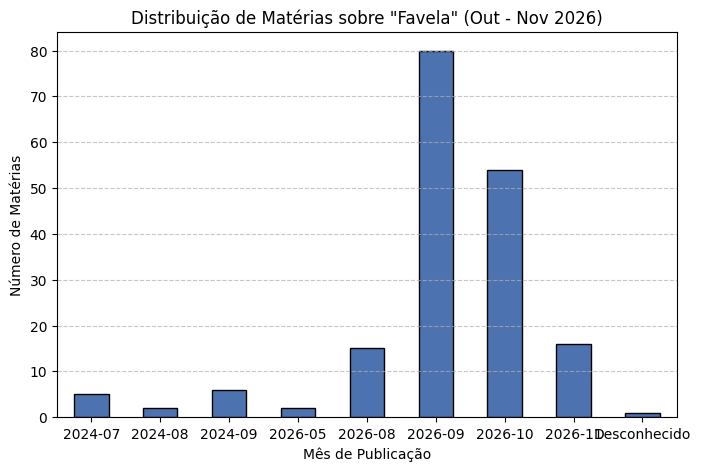

In [57]:
contagem_mes = df['ano_mes'].value_counts().sort_index()
print("Distribuição das matérias:")
print(contagem_mes)

# 3. Plota o gráfico atualizado
plt.figure(figsize=(8, 5))
contagem_mes.plot(kind='bar', color='#4C72B0', edgecolor='black')
plt.title('Distribuição de Matérias sobre "Favela" (Out - Nov 2026)')
plt.xlabel('Mês de Publicação')
plt.ylabel('Número de Matérias')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [58]:
# Mostra as URLs que ficaram com data desconhecida
print(df[df['ano_mes'] == 'Desconhecido']['url'].head(10))

46    https://extra.globo.com/extra-favelas/
Name: url, dtype: object


Carregando o spaCy e os dados...
Limpando os textos (removendo stop words e pontuações)...
Gerando a nuvem...


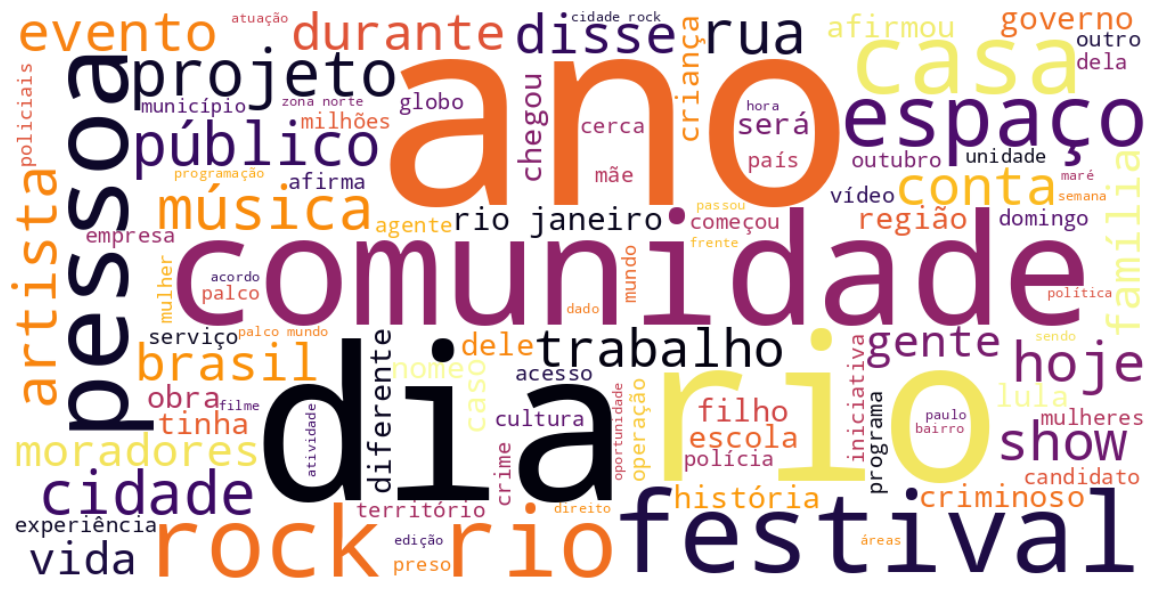

In [59]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Carrega o modelo de linguagem e a tabela
print("Carregando o spaCy e os dados...")
nlp = spacy.load("pt_core_news_sm")


# 2. Criando a função de limpeza com NLP
def limpar_texto(texto):
    # Processa o texto em minúsculas
    doc = nlp(str(texto).lower())
    
    tokens_limpos = []
    for token in doc:
        # Filtra: não é stop word, não é pontuação, é apenas texto (alpha) e tem mais de 2 letras
        if not token.is_stop and not token.is_punct and token.is_alpha and len(token.text) > 2:
            # Como vamos fazer nuvem, removemos a palavra da busca original para não enviesar o tamanho
            if token.text != "favela" and token.text != "favelas":
                tokens_limpos.append(token.text)
                
    return " ".join(tokens_limpos)

# 3. Aplicando a limpeza na coluna de textos (leva uns segundinhos)
print("Limpando os textos (removendo stop words e pontuações)...")
df['texto_limpo'] = df['texto'].apply(limpar_texto)

# 4. Gerando a Nuvem de Palavras
print("Gerando a nuvem...")
todas_palavras = " ".join(df['texto_limpo'])

wordcloud = WordCloud(
    width=1000, 
    height=500, 
    background_color='white', 
    colormap='inferno', # Um mapa de cores bem elegante e contrastante
    max_words=100
).generate(todas_palavras)

# 5. Plotando o resultado
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.tight_layout()
plt.show()

In [61]:
import pandas as pd

# Identificando matérias que mencionam "espaço favela" (ignorando maiúsculas/minúsculas)
mascara_espaco_favela = df['texto'].str.contains("espaço favela", case=False, na=False) | \
                        df['titulo'].str.contains("espaço favela", case=False, na=False)

# Criando o subcorpus limpo para a análise de enquadramento urbano
df_analise = df[~mascara_espaco_favela].copy()

# Criando o subcorpus do festival (para registro ou comparação)
df_espaco_favela = df[mascara_espaco_favela].copy()


print(f"Total de matérias no corpus consolidado: {len(df)}")
print(f"Matérias sobre 'Espaço Favela' isoladas: {len(df_espaco_favela)}")
print(f"Matérias no subcorpus final para a análise (urbana/social): {len(df_analise)}")

Total de matérias no corpus consolidado: 181
Matérias sobre 'Espaço Favela' isoladas: 34
Matérias no subcorpus final para a análise (urbana/social): 147


Aplicando limpeza avançada (apenas substantivos, verbos e adjetivos)...


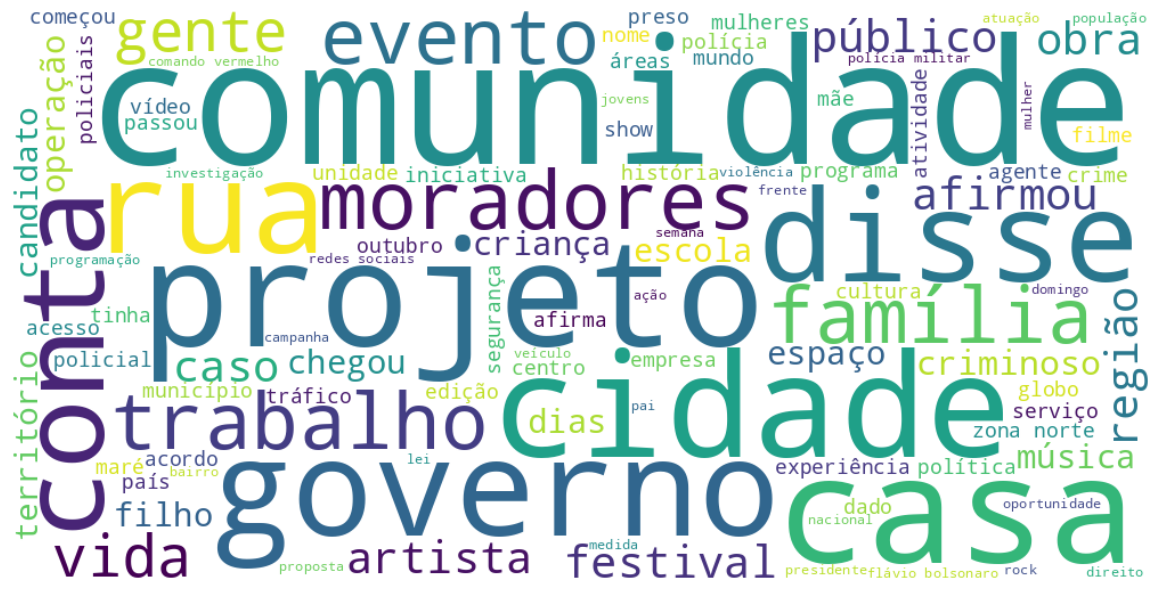

In [63]:
# Lista de palavras comuns em jornais que queremos ignorar para focar no tema central
stopwords_novas = ["ano", "anos","rio", "janeiro", "dia", "hoje", "ontem", "neste", "sobre", "pessoas", "pessoa", 
                        "diz", "segundo", "após", "onde"]

def limpar_texto_focado(texto):
    doc = nlp(str(texto).lower())
    tokens_limpos = []
    
    for token in doc:
        # 1. Filtra: não é stop word, pontuação e tem mais de 2 letras
        if not token.is_stop and not token.is_punct and token.is_alpha and len(token.text) > 2:
            
            # 2. Exclui palavras-chave do jornalês e a palavra de busca original
            if token.text not in stopwords_novas and token.text not in ["favela", "favelas"]:
                
                # 3. O "Pulo do Gato": Pega apenas Substantivos (NOUN), Adjetivos (ADJ) e verbos (VERB)
                if token.pos_ in ["NOUN", "ADJ", "VERB"]:
                    tokens_limpos.append(token.text)
                    
    return " ".join(tokens_limpos)

print("Aplicando limpeza avançada (apenas substantivos, verbos e adjetivos)...")
df_analise['texto_focado'] = df_analise['texto'].apply(limpar_texto_focado)

# Gerando a nova nuvem
todas_palavras_focadas = " ".join(df_analise['texto_focado'])

wordcloud_focada = WordCloud(
    width=1000, 
    height=500, 
    background_color='white', 
    colormap='viridis', # Trocando a cor para diferenciar da anterior
    max_words=100
).generate(todas_palavras_focadas)

# Plotando
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_focada, interpolation='bilinear')
plt.axis('off')
plt.tight_layout()
plt.show()

In [64]:
from collections import Counter

print("Extraindo Entidades Nomeadas (NER)...")

entidades_org = []
entidades_loc = []

# Usamos o texto original porque o spaCy precisa das letras maiúsculas (ex: "Prefeitura do Rio")
for texto in df_analise['texto']:
    doc = nlp(str(texto))
    for ent in doc.ents:
        # Filtramos as entidades pela etiqueta de Organização (ORG)
        if ent.label_ == "ORG":
            # Limpeza rápida para evitar sujeiras de pontuação
            entidade_limpa = ent.text.strip().strip('.,')
            if len(entidade_limpa) > 2:
                entidades_org.append(entidade_limpa)
                
        # Filtramos pela etiqueta de Localidade (LOC)
        elif ent.label_ == "LOC":
            entidade_limpa = ent.text.strip().strip('.,')
            if len(entidade_limpa) > 2:
                entidades_loc.append(entidade_limpa)

# Contando e pegando o Top 15 de cada
top_orgs = Counter(entidades_org).most_common(15)
top_locs = Counter(entidades_loc).most_common(15)

print("\nQUINZE INSTITUIÇÕES / ORGANIZAÇÕES MAIS CITADAS:")
for org, freq in top_orgs:
    print(f"- {org}: {freq} vezes")

print("\nQUINZE LOCAIS / TERRITÓRIOS MAIS CITADOS:")
for loc, freq in top_locs:
    print(f"- {loc}: {freq} vezes")

Extraindo Entidades Nomeadas (NER)...

QUINZE INSTITUIÇÕES / ORGANIZAÇÕES MAIS CITADAS:
- GLOBO: 31 vezes
- Maré: 28 vezes
- TV Globo: 26 vezes
- Polícia Civil: 25 vezes
- PSD: 24 vezes
- MPF: 21 vezes
- EXTRA: 17 vezes
- Terceiro Comando Puro: 15 vezes
- O Globo: 13 vezes
- CBN: 11 vezes
- Globo: 10 vezes
- Comando Vermelho: 10 vezes
- Peixão: 10 vezes
- UPPs: 9 vezes
- Justiça: 8 vezes

QUINZE LOCAIS / TERRITÓRIOS MAIS CITADOS:
- Rio: 192 vezes
- Brasil: 66 vezes
- Rio de Janeiro: 57 vezes
- São Gonçalo: 40 vezes
- Polícia Militar: 39 vezes
- Comando Vermelho: 38 vezes
- Rock in Rio: 37 vezes
- Siri: 30 vezes
- Zona Norte do Rio: 29 vezes
- Bolsonaro: 28 vezes
- Vidigal: 27 vezes
- Zona Norte: 27 vezes
- Complexo da Maré: 24 vezes
- Niterói: 24 vezes
- Baixada Fluminense: 24 vezes


In [65]:
print(df_analise[df_analise['texto'].str.contains("Peixão", case=False, na=False)]['texto'].values[0])

A Polícia Civil prendeu em flagrante, na quinta-feira, seis funcionários de uma empresa de telecomunicações suspeitos de participar de um esquema ligado ao Comando Vermelho (CV) para impor o monopólio do fornecimento de internet em Vila Isabel, na Zona Norte do Rio. Segundo a 20ª DP (Vila Isabel), o grupo cortava cabos de operadoras regulares e usava ameaças para obrigar moradores a contratar os serviços de uma empresa de fibra óptica.

Violência doméstica e psicológica:policial é preso em flagrante por manter ex-namorada, também PM, em cárcere privadoAnúncio em rede social:suspeito é preso com carro de luxo clonado avaliado em R$ 150 mil e comprado por R$ 10 mil

A investigação começou após informações de inteligência indicarem que moradores eram ameaçados para contratar exclusivamente os serviços da empresa. De acordo com os agentes, o grupo cortava sistematicamente os cabos de fibra óptica de operadoras regulares e impedia que técnicos dessas empresas realizassem os reparos necessár

In [68]:
print("Extraindo Entidades (NER) com filtros aplicados...")

# 1. Listas de ignorados (tudo em letras minúsculas para a verificação não falhar)
orgs_ignoradas = {
    "tv globo", "extra", "globo", "o globo", "cbn", "maré", "editora globo", "nós"
    }

# 2. Nova lista para limpar os falsos territórios
locs_ignoradas = {
    "bolsonaro", "rio", "rio de janeiro", "brasil"
}

entidades_org = []
entidades_loc = []

for texto in df_analise['texto']:
    doc = nlp(str(texto))
    for ent in doc.ents:
        entidade_limpa = ent.text.strip().strip('.,')
        entidade_lower = entidade_limpa.lower()
        
        # Filtramos tamanho mínimo de 2 letras
        if len(entidade_limpa) > 2:
            
            # Filtro para ORG
            if ent.label_ == "ORG" and entidade_lower not in orgs_ignoradas:
                entidades_org.append(entidade_limpa)
                
            # Filtro para LOC
            elif ent.label_ == "LOC" and entidade_lower not in locs_ignoradas:
                entidades_loc.append(entidade_limpa)

# Contando e pegando o Top 15
top_orgs = Counter(entidades_org).most_common(15)
top_locs = Counter(entidades_loc).most_common(15)

print("\nQUINZE INSTITUIÇÕES / ORGANIZAÇÕES MAIS CITADAS (FILTRADO):")
for org, freq in top_orgs:
    print(f"- {org}: {freq} vezes")

print("\nQUINZE LOCAIS / TERRITÓRIOS MAIS CITADOS (FILTRADO):")
for loc, freq in top_locs:
    print(f"- {loc}: {freq} vezes")

Extraindo Entidades (NER) com filtros aplicados...

QUINZE INSTITUIÇÕES / ORGANIZAÇÕES MAIS CITADAS (FILTRADO):
- Polícia Civil: 25 vezes
- PSD: 24 vezes
- MPF: 21 vezes
- Terceiro Comando Puro: 15 vezes
- Comando Vermelho: 10 vezes
- Peixão: 10 vezes
- UPPs: 9 vezes
- Justiça: 8 vezes
- TCU: 8 vezes
- Bolsa Família: 8 vezes
- CPA: 7 vezes
- CNJ: 7 vezes
- Ação da Cidadania: 7 vezes
- Tribunal Superior Eleitoral: 6 vezes
- Banco do Brasil: 6 vezes

QUINZE LOCAIS / TERRITÓRIOS MAIS CITADOS (FILTRADO):
- São Gonçalo: 40 vezes
- Polícia Militar: 39 vezes
- Comando Vermelho: 38 vezes
- Rock in Rio: 37 vezes
- Siri: 30 vezes
- Zona Norte do Rio: 29 vezes
- Vidigal: 27 vezes
- Zona Norte: 27 vezes
- Complexo da Maré: 24 vezes
- Niterói: 24 vezes
- Baixada Fluminense: 24 vezes
- Centro: 23 vezes
- Penha: 23 vezes
- São Paulo: 22 vezes
- Nordeste: 21 vezes


In [69]:
print("Extraindo Entidades: Pessoas (PER)...")

# 1. Lista de ruídos clássicos para Pessoas no jornalismo
# Muitas vezes o modelo confunde o repórter, fotógrafo ou termos genéricos com os personagens da matéria
per_ignoradas = {
    "extra", "leia mais", "foto", "veja", "vídeo"
}

entidades_per = []

for texto in df_analise['texto']:
    doc = nlp(str(texto))
    for ent in doc.ents:
        entidade_limpa = ent.text.strip().strip('.,')
        entidade_lower = entidade_limpa.lower()
        
        # Filtramos por tamanho mínimo para evitar lixo de 1 letra
        if len(entidade_limpa) > 2:
            
            # Filtro para PER (Pessoas)
            if ent.label_ == "PER" and entidade_lower not in per_ignoradas:
                entidades_per.append(entidade_limpa)
                
            
# Contando e pegando o Top 15
top_per = Counter(entidades_per).most_common(15)


print("\nQUINZE PESSOAS MAIS CITADAS (PER):")
for pessoa, freq in top_per:
    print(f"- {pessoa}: {freq} vezes")



Extraindo Entidades: Pessoas (PER)...

QUINZE PESSOAS MAIS CITADAS (PER):
- Lula: 96 vezes
- Flávio Bolsonaro: 49 vezes
- PSOL: 48 vezes
- Ruas: 41 vezes
- Jair Bolsonaro: 31 vezes
- Castro: 30 vezes
- Paes: 26 vezes
- Flávio: 21 vezes
- Siri: 20 vezes
- Eduardo Paes: 17 vezes
- Garotinho: 16 vezes
- Douglas: 15 vezes
- Cláudio Castro: 15 vezes
- Alvinho: 13 vezes
- Renan: 13 vezes


Vamos complementar a investigação das categorias de entidades em uma etapa posterior deste projeto, em que utlizaremos um LLM.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

print("Extraindo os Trigramas do corpus...\n")

# 1. Definimos nossas próprias stop words em português para não termos bigramas como "a policia" ou "o morro"
stopwords_pt = [
    "a", "o", "as", "os", "de", "do", "da", "dos", "das", "em", "no", "na", "nos", "nas", 
    "para", "por", "com", "um", "uma", "uns", "umas", "que", "se", "é", "são", "ao", "aos",
    "pelo", "pela", "pelos", "pelas", "como", "mas", "ou", "e", "não", "mais"
]

# 3. Configura a ferramenta para pegar Trios (ngram_range=(3,3))
vectorizer_trigrams = CountVectorizer(ngram_range=(3, 3), stop_words=stopwords_pt)
X_trigrams = vectorizer_trigrams.fit_transform(df_analise['texto'].fillna(''))

# Soma a frequência de cada trio
sum_trigrams = X_trigrams.sum(axis=0) 
frequencia_trigrams = [(word, sum_trigrams[0, idx]) for word, idx in vectorizer_trigrams.vocabulary_.items()]

# Ordena do maior para o menor e pega os 15 primeiros
df_trigrams = pd.DataFrame(frequencia_trigrams, columns=['Trigrama', 'Frequência'])
df_trigrams = df_trigrams.sort_values(by='Frequência', ascending=False).head(15)

print("\nOS QUINZE TRIGRAMAS MAIS FREQUENTES:")
for index, row in df_trigrams.iterrows():
    print(f"- {row['Trigrama']}: {row['Frequência']} vezes")

Extraindo os Bigramas e Trigramas do corpus...


OS QUINZE TRIGRAMAS MAIS FREQUENTES:
- rock in rio: 51 vezes
- zona norte rio: 33 vezes
- fato veja quê: 30 vezes
- declaração fato veja: 30 vezes
- nãoébemassim veja quê: 21 vezes
- terceiro comando puro: 18 vezes
- comando puro tcp: 17 vezes
- governo jair bolsonaro: 16 vezes
- comando vermelho cv: 16 vezes
- estado rio janeiro: 15 vezes
- supremo tribunal federal: 15 vezes
- tribunal federal stf: 14 vezes
- zona sudoeste rio: 14 vezes
- zona sul rio: 12 vezes
- assembleia legislativa rio: 11 vezes


Limpando ruídos e gerando o gráfico de trigramas...


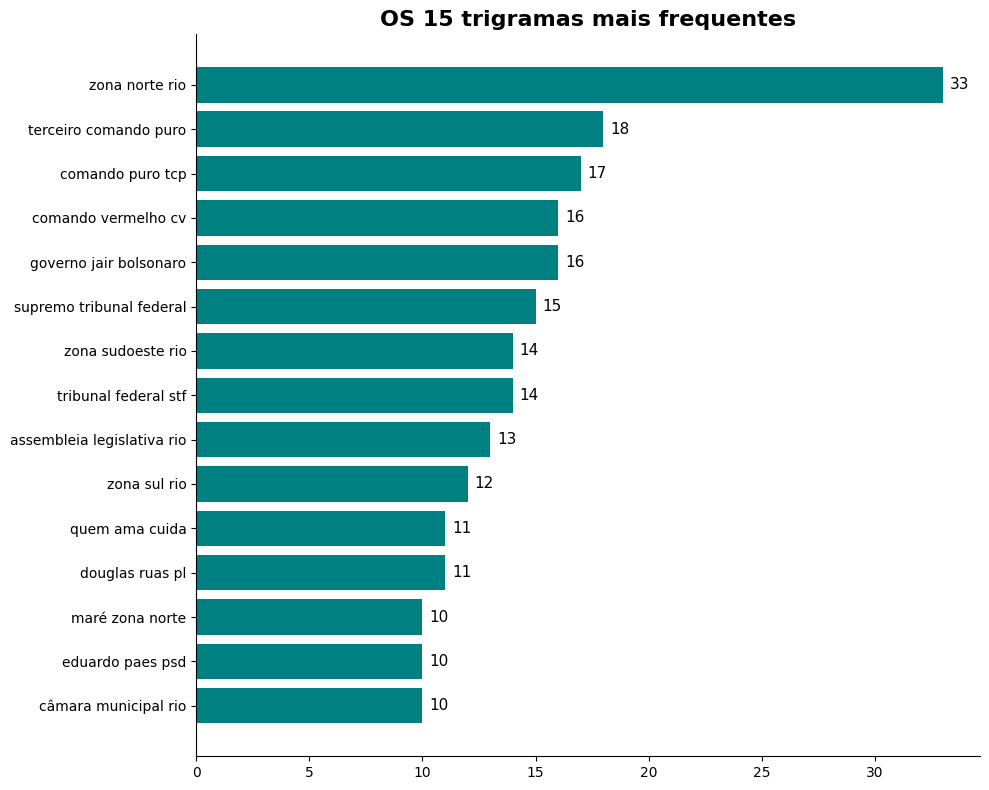

In [74]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

print("Limpando ruídos e gerando o gráfico de trigramas...")

# 1. Atualizando as Stop Words com o ruído de layout do site
stopwords_pt = [
    "a", "o", "as", "os", "de", "do", "da", "dos", "das", "em", "no", "na", "nos", "nas", 
    "para", "por", "com", "um", "uma", "uns", "umas", "que", "se", "é", "são", "ao", "aos",
    "pelo", "pela", "pelos", "pelas", "como", "mas", "ou", "e", "não", "mais",
    # O nosso escudo contra o "Boilerplate" do Extra:
    "declaração", "fato", "veja", "quê", "nãoébemassim", "fórum", "extra", "rock", "estado"
]

# 2. Extraindo os Trigramas limpos
vectorizer_trigrams = CountVectorizer(ngram_range=(3, 3), stop_words=stopwords_pt)
X_trigrams = vectorizer_trigrams.fit_transform(df_analise['texto'].fillna(''))

sum_trigrams = X_trigrams.sum(axis=0) 
frequencia_trigrams = [(word, sum_trigrams[0, idx]) for word, idx in vectorizer_trigrams.vocabulary_.items()]

# Organiza o Top 15
df_trigrams = pd.DataFrame(frequencia_trigrams, columns=['Trigrama', 'Frequência'])
df_trigrams = df_trigrams.sort_values(by='Frequência', ascending=False).head(15)

# 3. Plotando o Gráfico de Barras Horizontais
plt.figure(figsize=(10, 8))

# Invertemos a ordem do dataframe apenas para o gráfico (para o maior ficar no topo)
df_plot = df_trigrams.sort_values(by='Frequência', ascending=True)

# Cria as barras usando a cor "teal" (verde-azulado) que dá um tom acadêmico bem elegante
barras = plt.barh(df_plot['Trigrama'], df_plot['Frequência'], color='teal')

# Ajustes de texto e design
plt.xlabel('')
plt.ylabel('')
plt.title('OS 15 trigramas mais frequentes', fontsize=16, fontweight='bold')

# Adicionando o número exato ao lado de cada barra para facilitar a leitura
for barra in barras:
    plt.text(
        barra.get_width() + 0.3, # Posição X (um pouquinho à direita da barra)
        barra.get_y() + barra.get_height() / 2, # Posição Y (no meio da barra)
        f"{int(barra.get_width())}", 
        va='center', 
        fontsize=11
    )

# Remove as bordas do topo e da direita para deixar o gráfico mais "limpo" (estilo Tufte)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Em vez de olharmos os adjetivos e verbos do texto inteiro (o que traria muito ruído genérico), vamos programar o spaCy para fazer uma varredura de Dependência Sintática e POS Tagging:

* O código vai ler todas as matérias do corpus em busca da palavra "favela" (ou "favelas").

* Quando encontrar, ele vai olhar a frase inteira e pescar especificamente os Adjetivos (ADJ) que estão modificando a palavra "favela" e os Verbos (VERB) dos quais ela é o sujeito ou o objeto direto.

In [75]:

print("Executando POS Tagging e extração de vizinhança da palavra 'favela'...")

nlp = spacy.load("pt_core_news_sm")

adjetivos_favela = []
verbos_favela = []

for texto in df_analise['texto']:
    doc = nlp(str(texto))
    
    # Varre cada token da matéria
    for token in doc:
        # Encontrou variações da palavra-chave
        if token.text.lower() in ["favela", "favelas"]:
            
            # 1. Olhando os filhos sintáticos (adjetivos que qualificam a favela diretamente)
            for filho in token.children:
                if filho.pos_ == "ADJ":
                    adjetivos_favela.append(filho.text.lower())
                    
            # 2. Olhando o pai sintático (o verbo que comanda a favela ou do qual ela é alvo/sujeito)
            if token.head.pos_ == "VERB":
                verbos_favela.append(token.head.text.lower())

# Contando os resultados
top_adj = Counter(adjetivos_favela).most_common(15)
top_verbs = Counter(verbos_favela).most_common(15)

print("\nADJETIVOS ASSOCIADOS DIRETAMENTE A 'FAVELA':")
if top_adj:
    for adj, freq in top_adj:
        print(f"- {adj}: {freq} vezes")
else:
    print("Nenhum adjetivo direto encontrado na estrutura sintática.")

print("\nVERBOS ASSOCIADOS DIRETAMENTE A 'FAVELA':")
if top_verbs:
    for verb, freq in top_verbs:
        print(f"- {verb}: {freq} vezes")
else:
    print("Nenhum verbo direto encontrado na estrutura sintática.")

Executando POS Tagging e extração de vizinhança da palavra 'favela'...

ADJETIVOS ASSOCIADOS DIRETAMENTE A 'FAVELA':
- cariocas: 4 vezes
- vizinha: 1 vezes
- seguro: 1 vezes
- carioca: 1 vezes
- próprias: 1 vezes
- seguras: 1 vezes
- retomadas: 1 vezes

VERBOS ASSOCIADOS DIRETAMENTE A 'FAVELA':
- aproximar: 3 vezes
- criada: 3 vezes
- engolida: 3 vezes
- promovido: 2 vezes
- ocupa: 2 vezes
- sair: 2 vezes
- cresceu: 2 vezes
- integra: 2 vezes
- mora: 2 vezes
- venceu: 2 vezes
- criado: 2 vezes
- projetava: 2 vezes
- crescer: 2 vezes
- debaterá: 1 vezes
- cantando: 1 vezes


In [76]:
print("Executando extração avançada: A favela como sujeito (com lematização)...")

nlp = spacy.load("pt_core_news_sm")
verbos_sujeito_favela = []

for texto in df_analise['texto']:
    doc = nlp(str(texto))
    
    for token in doc:
        # Se encontramos a palavra-chave
        if token.text.lower() in ["favela", "favelas"]:
            
            # Verificamos se o "pai" sintático deste token é um verbo
            verbo_pai = token.head
            if verbo_pai.pos_ == "VERB":
                
                # Verificamos a relação de dependência sintática entre a favela e o verbo
                # 'nsubj' = sujeito nominal | 'nsubj:pass' = sujeito passivo
                if token.dep_ in ["nsubj", "nsubj:pass"]:
                    
                    # Pegamos o LEMA do verbo (o infinitivo: cresceu/crescer -> crescer)
                    verbos_sujeito_favela.append(verbo_pai.lemma_.lower())

# Contando os resultados
top_verbos_sujeito = Counter(verbos_sujeito_favela).most_common(15)

print("\nVERBOS DOS QUAIS 'FAVELA' É O SUJEITO (Lematizados):")
if top_verbos_sujeito:
    for verb, freq in top_verbos_sujeito:
        print(f"- {verb}: {freq} vezes")
else:
    print("Nenhum verbo encontrado onde a favela atue estritamente como sujeito nesta amostra.")

Executando extração avançada: A favela como sujeito (com lematização)...

VERBOS DOS QUAIS 'FAVELA' É O SUJEITO (Lematizados):
- engoler: 3 vezes
- integrar: 2 vezes
- vencer: 2 vezes
- criar: 2 vezes
- reunir: 2 vezes
- debater: 1 vezes
- querer: 1 vezes
- ter: 1 vezes
- poder: 1 vezes
- celebra: 1 vezes
- proporcionar: 1 vezes
- realizar: 1 vezes
- venceu'vai: 1 vezes
- receber: 1 vezes
- enxergar: 1 vezes


In [ ]:
print("Executando extração com separação de agência (Ativa vs Passiva)...")

nlp = spacy.load("pt_core_news_sm")

verbos_voz_ativa = []
verbos_voz_passiva = []

for texto in df_analise['texto']:
    doc = nlp(str(texto))
    
    for token in doc:
        if token.text.lower() in ["favela", "favelas"]:
            verbo_pai = token.head
            
            if verbo_pai.pos_ == "VERB":
                # Caso 1: Sujeito Ativo (A favela age / faz)
                if token.dep_ == "nsubj":
                    verbos_voz_ativa.append(verbo_pai.lemma_.lower())
                
                # Caso 2: Sujeito Passivo (A favela sofre a ação / é alvo)
                elif token.dep_ == "nsubj:pass":
                    verbos_voz_passiva.append(verbo_pai.lemma_.lower())

# Contabilizando os resultados
top_ativa = Counter(verbos_voz_ativa).most_common(15)
top_passiva = Counter(verbos_voz_passiva).most_common(15)

print("\nVOZ ATIVA: O que a Favela FAZ (Sujeito Ativo - nsubj):")
if top_ativa:
    for verb, freq in top_ativa:
        print(f"- {verb}: {freq} vezes")
else:
    print("Nenhum verbo na voz ativa encontrado.")

print("\nVOZ PASSIVA: O que ACONTECE com a Favela (Sujeito Passivo - nsubj:pass):")
if top_passiva:
    for verb, freq in top_passiva:
        print(f"- {verb}: {freq} vezes")
else:
    print("Nenhum verbo na voz passiva encontrado.")

Executando extração com separação de agência (Ativa vs Passiva)...
